# 02 - Modeling
Perbandingan beberapa model non-neural-network di dalam **Pipeline + ColumnTransformer**, pada subset 20% data (hanya untuk perbandingan cepat). Model final dilatih penuh lewat `scripts/train.py`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd().parent))  # agar `scripts` bisa di-import dari folder notebooks/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scripts.config import *
from scripts.preprocess import load_data, encode_target
sns.set_theme(style='whitegrid')
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier
from scripts.feature_engineering import BuildingFeatureAdder
from scripts.preprocess import build_preprocessor, DERIVED_NUM
from scripts.models import build_pipeline

train, _ = load_data()
sub = train.sample(frac=0.2, random_state=SEED)
X, y = sub.drop(columns=[TARGET]), encode_target(sub[TARGET])
Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

## Baseline linear (OvR dan OvO) dengan one-hot + scaling
Sesuai materi multiclass: One-vs-Rest dan One-vs-One dengan Logistic Regression.

In [2]:
def linear_pre():
    num = NUM_COLS + DERIVED_NUM
    return ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT_COLS + GEO_COLS),
    ])
def lin(strategy):
    return Pipeline([('fe', BuildingFeatureAdder(use_serial=False)), ('pre', linear_pre()),
                     ('clf', strategy(LogisticRegression(max_iter=300, C=1.0)))])
models = {
    'Logistic OvR': lin(OneVsRestClassifier),
    'Logistic OvO': lin(OneVsOneClassifier),
    'Random Forest': Pipeline([('fe', BuildingFeatureAdder(use_serial=False)), ('pre', build_preprocessor(False)),
                               ('clf', RandomForestClassifier(300, min_samples_leaf=3, n_jobs=-1, random_state=SEED))]),
    'HistGradientBoosting': Pipeline([('fe', BuildingFeatureAdder(use_serial=False)), ('pre', build_preprocessor(False)),
                               ('clf', HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED))]),
    'LightGBM (final family)': build_pipeline(n_estimators=300),
}
rows = []
for name, m in models.items():
    m.fit(Xa, ya); p = m.predict(Xb)
    rows.append(dict(model=name, accuracy=accuracy_score(yb,p), macro_f1=f1_score(yb,p,average='macro'),
                     qwk=cohen_kappa_score(yb,p,weights='quadratic')))
res = pd.DataFrame(rows).set_index('model').round(4).sort_values('accuracy', ascending=False)
res

,accuracy,macro_f1,qwk
model,,,
Random Forest,0.5601,0.5146,0.7046
LightGBM (final family),0.5597,0.5145,0.7045
HistGradientBoosting,0.5564,0.5092,0.7027
Logistic OvO,0.5510,0.4992,0.6943
Logistic OvR,0.5499,0.4955,0.6908


Pada subset kecil (sekitar 80 ribu baris) semua model berselisih hanya sekitar 1 poin akurasi; Random Forest dan LightGBM praktis setara, model linear OvR/OvO sedikit di bawahnya. **LightGBM** tetap dipilih karena bisa dituning dan skornya naik jelas saat dilatih pada seluruh data (sekitar 0.588 pada 5-fold CV), serta lebih cepat untuk prediksi. Perbandingan ini hanya satu split, jadi selisih kecil antar model belum tentu signifikan.

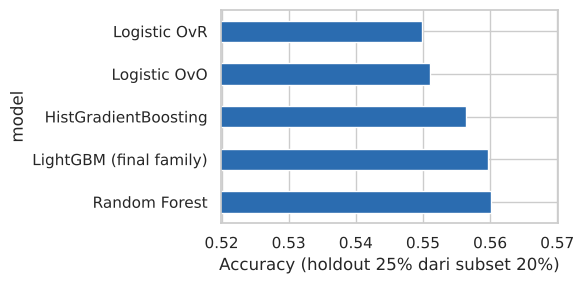

In [3]:
res.accuracy.plot.barh(color='#2b6cb0', figsize=(6,3)); plt.xlabel('Accuracy (holdout 25% dari subset 20%)'); plt.xlim(res.accuracy.min()-0.03, res.accuracy.max()+0.01); plt.tight_layout(); plt.show()

## Hasil model final
Hasil lengkap (holdout 20% dan 5-fold CV pada seluruh train) dicetak oleh `python -m scripts.train --cv`, dan figur disimpan di `reports/figures/`.

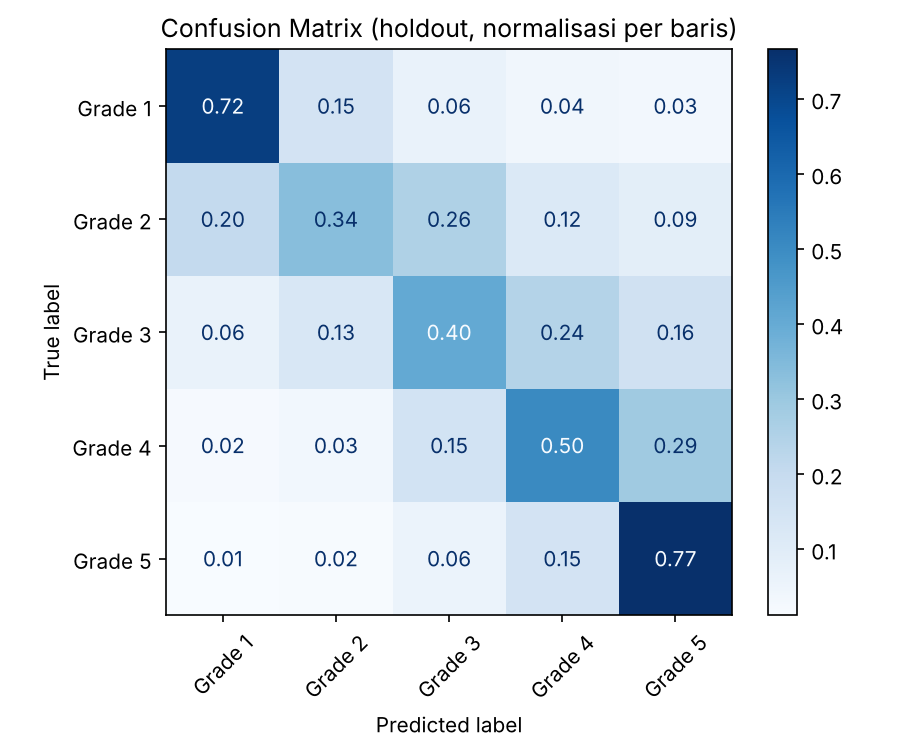

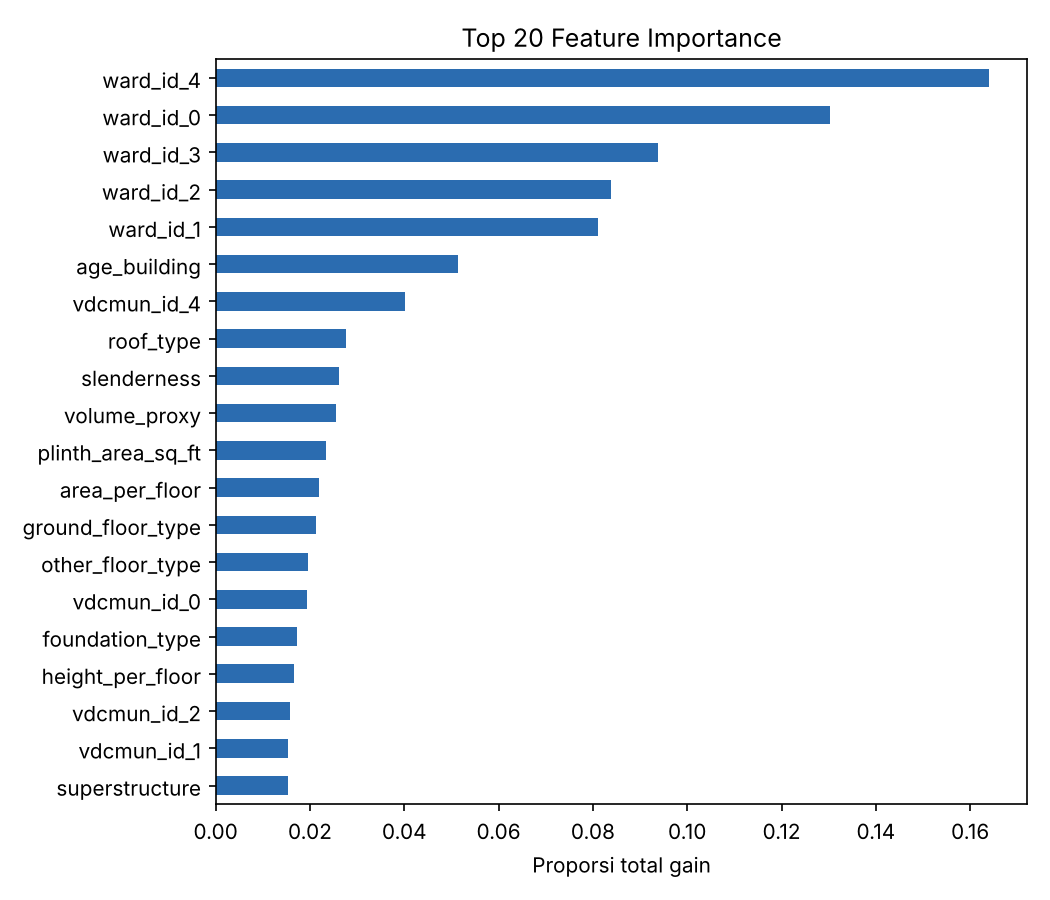

In [4]:
from IPython.display import Image, display
display(Image(FIG_DIR/'confusion_matrix.png', width=420)); display(Image(FIG_DIR/'feature_importance.png', width=520))